Cell 1 - Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import shap

from xgboost import XGBRegressor

c:\Users\NickK\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cell 2 - Load data

In [2]:
BASE_DIR = Path(
    r"C:\Users\NickK\OneDrive\Υπολογιστής\github\kaggle_store_sales_forecasting"
)

ADVANCED_DIR = BASE_DIR / "data" / "advanced"

train = pd.read_csv(
    ADVANCED_DIR / "train_advanced.csv"
)

train["date"] = pd.to_datetime(
    train["date"]
)

print(train.shape)

(3000888, 29)


Cell 3 - Create feature matrix

In [3]:
target = "sales"

features = [
    "store_nbr",
    "family",
    "onpromotion",

    "year",
    "month",
    "day",
    "quarter",
    "week",
    "day_of_week",
    "is_weekend",

    "city",
    "state",
    "type",
    "cluster",

    "dcoilwtico",
    "is_payday",
    "is_national_holiday",
    "earthquake_period",

    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",

    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",

    "rolling_std_7",
    "rolling_std_28"
]

X = train[features]

y = np.log1p(
    train[target]
)

X = pd.get_dummies(
    X,
    drop_first=True
)

print(X.shape)

(3000888, 94)


Cell 4 - Sample data

In [4]:
sample_idx = X.sample(
    n=5000,
    random_state=42
).index

X_sample = X.loc[sample_idx]
y_sample = y.loc[sample_idx]

print(X_sample.shape)

(5000, 94)


Cell 5 - Train smaller model

In [5]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_sample,
    y_sample
)

print("Model trained.")

Model trained.


Cell 6 - SHAP Explainer

In [6]:
explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_sample
)

print("SHAP values calculated.")

SHAP values calculated.


Cell 7 - Global Importance Plot

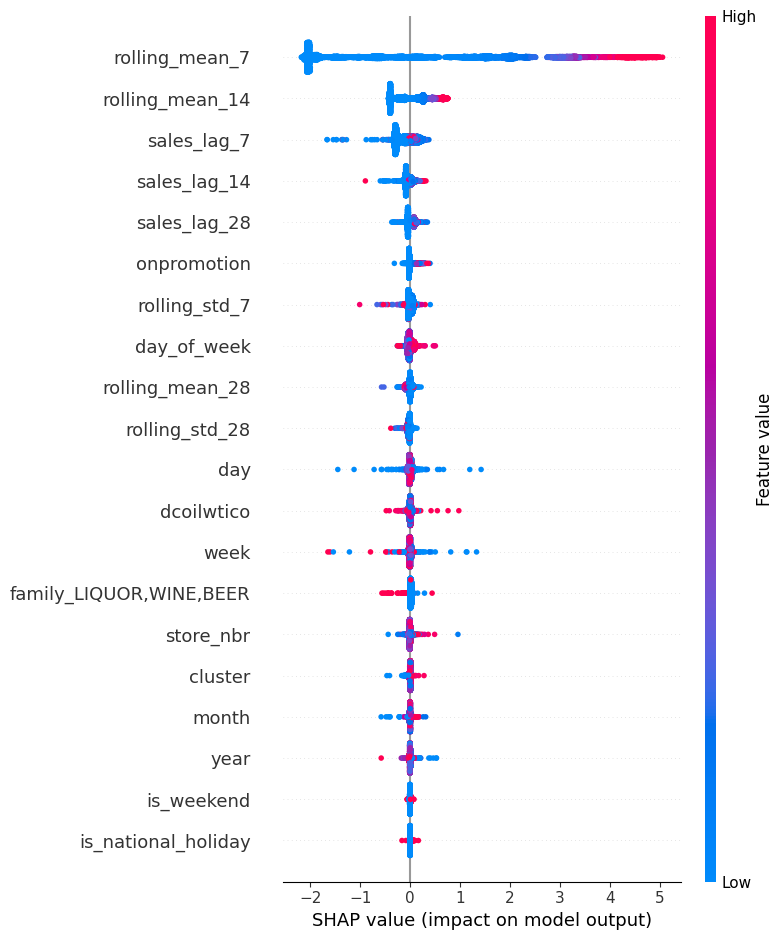

In [7]:
shap.summary_plot(
    shap_values,
    X_sample,
    show=False
)

Cell 8 - Bar Plot

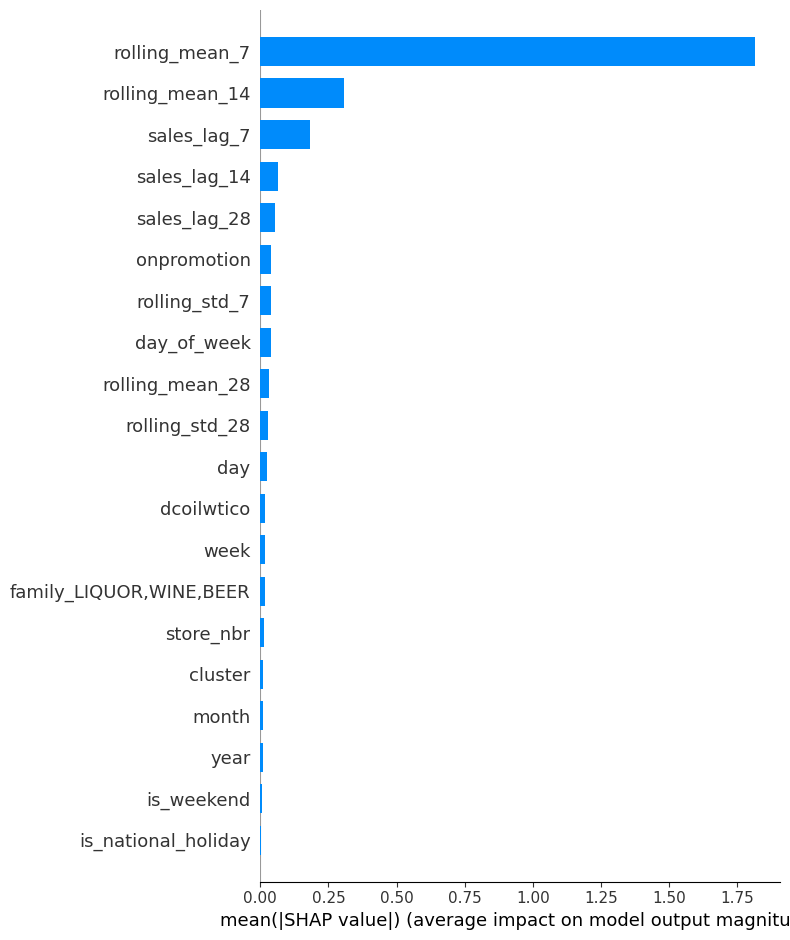

In [8]:
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar",
    show=False
)